# Atelier AI — Historical Training Dataset

**Current milestone: 4.4e — training-group eligibility and aligned ranker inputs.** Preserve the full historical candidate exports, select informative training-only groups, and prepare aligned X, y and contiguous group sizes without fitting a model. This notebook runs independently of notebook 03, using its exported cohort.

## Goal

At cutoff `t`, use only data before `t` for candidates and features. Define purchase relevance over `[t, t + 7 days)`. Sections 1–7 prepare reference targets; sections 8–13 recompute historical candidates/features and join those labels without adding missed purchases.

**Scope:** four target weeks, the same fixed 20,000 customers, no fitted model and no local-test outcomes. Four weeks are an initial computational scope, fixed before viewing these outcomes, not an optimal training duration or a temporal cross-validation study.

### Key assumptions and conventions

- Every interval includes its start and excludes its end. Training target windows end no later than 9 September 2020.
- A relevant item is a distinct observed customer–article purchase within one target week. Source repetitions are retained in the audit transactions but deduplicated for relevance.
- Customers without target purchases remain in the full population; future MAP/Recall eligibility follows the existing evaluation protocol.
- No observed purchase means label 0 for a generated candidate, not proof of dislike or absence of exposure.
- Features use 180-day history and 7-day global popularity at **each** cutoff. Validation-cutoff features cannot be reused as historical training features.
- Metadata stability remains an explicit unverified assumption from notebook 03; this milestone does not read article metadata.

## 1. Setup

Copy `src/atelier_ai/training_targets.py` and `tests/test_training_targets.py` into the project, then restart the project kernel. Run `python -m pytest -q`.

Save this notebook as `notebooks/04_training_dataset.ipynb` before Run All. The export records its saved code fingerprint. Existing dependencies are sufficient.

In [1]:
from hashlib import sha256
from pathlib import Path
from tempfile import TemporaryDirectory
import json
import os
import platform
import shutil

import duckdb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd
import seaborn as sns
import atelier_ai
import atelier_ai.training_targets as training_targets_module
from atelier_ai.data_io import read_source_csv, read_source_chunks
from atelier_ai.feature_export import file_sha256
from atelier_ai.training_targets import (
    make_training_schedule, validate_training_schedule, collect_training_transactions,
    build_training_targets, label_candidate_pairs,
)

PROJECT_ROOT = Path(atelier_ai.__file__).resolve().parents[2]
VALIDATION_CUTOFF = pd.Timestamp("2020-09-09")
LOCAL_TEST_CUTOFF = pd.Timestamp("2020-09-16")
HORIZON_DAYS = 7
HISTORY_DAYS = 180
POPULARITY_DAYS = 7
TRAINING_WEEKS = 4
SOURCE_CHUNK_ROWS = 500_000
EXPECTED_COHORT_SHA256 = "f83b0240971fbc17545f900c497a904cb4e4c51b5bcaba64f0df6ceb4dc6b96f"
VALIDATION_FEATURE_DATASET = Path(os.environ.get(
    "ATELIER_VALIDATION_FEATURE_DATASET",
    PROJECT_ROOT / "data/processed/features/validation_2020-09-09_1e4ed94c9d17",
))
TRAINING_TARGET_OUTPUT_BASE = Path(os.environ.get(
    "ATELIER_TRAINING_TARGET_OUTPUT_DIR", PROJECT_ROOT / "data/processed/training_targets"
))
TRAINING_NOTEBOOK_PATH = Path(os.environ.get(
    "ATELIER_TRAINING_NOTEBOOK", PROJECT_ROOT / "notebooks/04_training_dataset.ipynb"
))
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
print("Project:", PROJECT_ROOT)
print("Cohort source:", VALIDATION_FEATURE_DATASET)
print("Target output base:", TRAINING_TARGET_OUTPUT_BASE)

Project: /Users/oumar/Developer/portfolio/atelier-ai-project
Cohort source: /Users/oumar/Developer/portfolio/atelier-ai-project/data/processed/features/validation_2020-09-09_1e4ed94c9d17
Target output base: /Users/oumar/Developer/portfolio/atelier-ai-project/data/processed/training_targets


## 2. Reuse the exact exported cohort

Read the cohort from the verified validation feature export. Verify its checksum, unique IDs and the established cohort fingerprint. Do not select historical buyers or sample again.

The manifest's raw-source identity must agree with the current source manifest. This checks provenance and current file sizes, without rehashing all raw CSV bytes or rereading six million validation feature rows.

In [2]:
validation_manifest = json.loads((VALIDATION_FEATURE_DATASET / "manifest.json").read_text())
if validation_manifest["status"] != "complete" or pd.Timestamp(validation_manifest["cutoff"]) != VALIDATION_CUTOFF:
    raise ValueError("Choose the complete validation-cutoff export from milestone 4.4b.")
cohort_path = VALIDATION_FEATURE_DATASET / "cohort.csv"
cohort_record = next(item for item in validation_manifest["support_files"] if item["file"] == "cohort.csv")
if file_sha256(cohort_path) != cohort_record["sha256"]:
    raise ValueError("Exported cohort checksum differs from its manifest.")
training_cohort = read_source_csv(cohort_path)
training_customer_ids = pd.Index(training_cohort["customer_id"], name="customer_id")
training_cohort_sha256 = sha256("\n".join(sorted(training_customer_ids)).encode()).hexdigest()
if len(training_customer_ids) != 20_000 or not training_customer_ids.is_unique or training_customer_ids.isna().any():
    raise ValueError("The established 20,000-customer cohort is required.")
if training_cohort_sha256 != EXPECTED_COHORT_SHA256:
    raise ValueError("Training cohort differs from the fixed validation cohort.")
source_manifest_path = PROJECT_ROOT / "docs/data_manifest.json"
source_manifest = json.loads(source_manifest_path.read_text())
if file_sha256(source_manifest_path) != validation_manifest["provenance"]["source_manifest_sha256"]:
    raise ValueError("Raw source manifest differs from the validation export's provenance.")
for item in source_manifest["files"]:
    if (PROJECT_ROOT / item["path"]).stat().st_size != item["size_bytes"]:
        raise ValueError(f"Raw source size differs: {item['path']}")
print("Cohort customers:", len(training_customer_ids))
print("Cohort SHA-256:", training_cohort_sha256)

Cohort customers: 20000
Cohort SHA-256: f83b0240971fbc17545f900c497a904cb4e4c51b5bcaba64f0df6ceb4dc6b96f


## 3. Fix four complete historical target weeks

Choose the last four complete seven-day windows before validation. Every target ends on or before the validation cutoff. Full 180-day source coverage exists for all four historical feature windows.

Adjacent **target** windows do not overlap. Their **history** windows deliberately overlap. A purchase used as an earlier training label can later become historical input once it has occurred; that is available information at the later cutoff.

The same customer may appear across weeks. The evaluation split tests future-week recommendation to this fixed population; it does not estimate performance on an entirely unseen customer population.

In [3]:
training_schedule = make_training_schedule(
    validation_cutoff=VALIDATION_CUTOFF, n_weeks=TRAINING_WEEKS,
    horizon_days=HORIZON_DAYS, history_days=HISTORY_DAYS, popularity_days=POPULARITY_DAYS,
)
if not training_schedule["history_start"].ge(pd.Timestamp("2018-09-20")).all():
    raise ValueError("A training history begins before observed source coverage.")
print(training_schedule.to_string(index=False))

    cutoff history_start popularity_start target_end
2020-08-12    2020-02-14       2020-08-05 2020-08-19
2020-08-19    2020-02-21       2020-08-12 2020-08-26
2020-08-26    2020-02-28       2020-08-19 2020-09-02
2020-09-02    2020-03-06       2020-08-26 2020-09-09


### Visualise available history and future target windows

The left panel shows the complete history span; the right panel zooms into target weeks. Validation/test dates are protocol boundaries only. No validation/test target rows are extracted by this notebook.

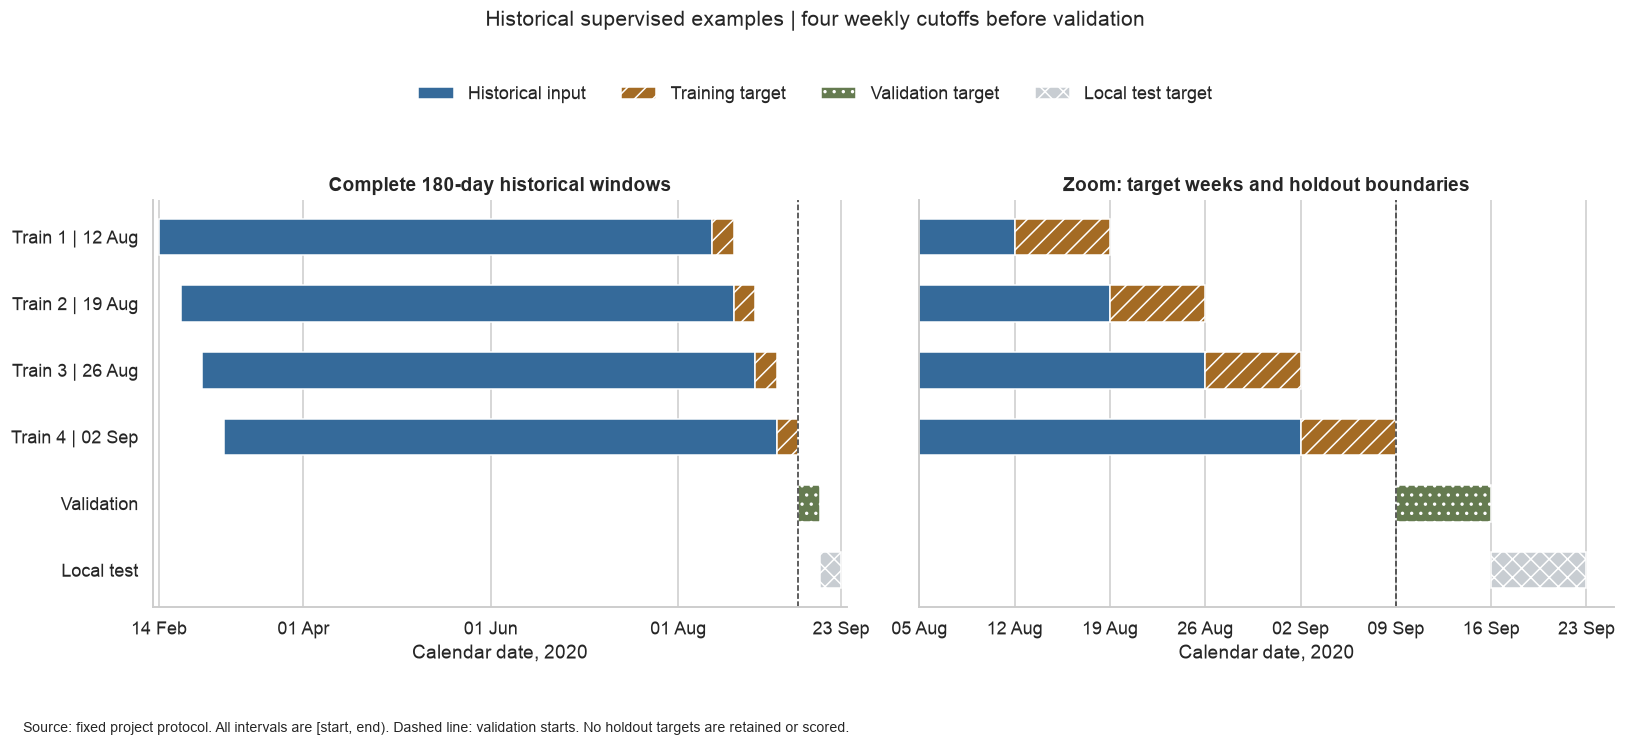

In [4]:
fig_training_windows, axes = plt.subplots(1, 2, figsize=(15, 6.8), sharey=True)
rows = list(training_schedule.itertuples(index=False))
row_labels = [f"Train {i + 1} | {row.cutoff:%d %b}" for i, row in enumerate(rows)] + ["Validation", "Local test"]
for ax in axes:
    for y, row in enumerate(rows):
        ax.barh(y, (row.cutoff-row.history_start).days, left=mdates.date2num(row.history_start),
                color="#356A9A", height=0.55)
        ax.barh(y, HORIZON_DAYS, left=mdates.date2num(row.cutoff), color="#A46B24", height=0.55,
                edgecolor="white", hatch="//")
    ax.barh(4, HORIZON_DAYS, left=mdates.date2num(VALIDATION_CUTOFF), color="#657B50", height=0.55, hatch="..")
    ax.barh(5, HORIZON_DAYS, left=mdates.date2num(LOCAL_TEST_CUTOFF), color="#C8CDD2", height=0.55, hatch="xx")
    ax.axvline(mdates.date2num(VALIDATION_CUTOFF), color="#333333", linestyle="--", linewidth=1)
    ax.set_yticks(range(6), row_labels)
    ax.xaxis_date()
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Calendar date, 2020")
axes[0].set_xlim(mdates.date2num(training_schedule["history_start"].min())-2,
                 mdates.date2num(LOCAL_TEST_CUTOFF + pd.Timedelta(days=7))+2)
full_window_ticks = [training_schedule["history_start"].min(), pd.Timestamp("2020-04-01"),
                     pd.Timestamp("2020-06-01"), pd.Timestamp("2020-08-01"),
                     LOCAL_TEST_CUTOFF + pd.Timedelta(days=7)]
axes[0].set_xticks([mdates.date2num(value) for value in full_window_ticks])
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[0].set_title("Complete 180-day historical windows")
axes[1].set_xlim(mdates.date2num(training_schedule["cutoff"].min())-7,
                 mdates.date2num(LOCAL_TEST_CUTOFF + pd.Timedelta(days=7))+2)
axes[1].xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.WE, interval=1))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[1].set_title("Zoom: target weeks and holdout boundaries")
axes[0].invert_yaxis()
sns.despine(fig=fig_training_windows)
fig_training_windows.legend(handles=[
    Patch(facecolor="#356A9A", label="Historical input"),
    Patch(facecolor="#A46B24", hatch="//", label="Training target"),
    Patch(facecolor="#657B50", hatch="..", label="Validation target"),
    Patch(facecolor="#C8CDD2", hatch="xx", label="Local test target"),
], loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.91), frameon=False)
fig_training_windows.suptitle("Historical supervised examples | four weekly cutoffs before validation", y=0.99, fontsize=14)
fig_training_windows.tight_layout(rect=(0, 0.09, 1, 0.85))
fig_training_windows.text(0.02, 0.025, "Source: fixed project protocol. All intervals are [start, end). Dashed line: validation starts. No holdout targets are retained or scored.", fontsize=9)
plt.show()

## 4. Check label semantics on explicitly synthetic rows

This fixture contains repeated purchases, the same article across two weeks, an outside-cohort customer and a validation-boundary purchase. Labels join on **cutoff, customer and article**.

The left join keeps candidate rows in their original order; it does not insert purchased items absent from the candidate set. Full reference relevance is preserved separately for future candidate-coverage and ranking evaluation.

In [5]:
fixture_schedule = make_training_schedule(validation_cutoff=VALIDATION_CUTOFF, n_weeks=2)
fixture_ids = pd.Index(["001", "002"], dtype="string")
fixture_columns = ["t_dat", "customer_id", "article_id"]
fixture_chunks = [pd.DataFrame(values, columns=fixture_columns, dtype="string") for values in [
    [["2020-08-26", "001", "01"], ["2020-09-01", "001", "01"],
     ["2020-09-02", "001", "02"], ["2020-09-09", "001", "future"],
     ["2020-08-27", "outside", "99"]],
    [["2020-08-27", "001", "01"], ["2020-09-08", "001", "01"]],
]]
fixture_transactions = collect_training_transactions(
    iter(fixture_chunks), fixture_ids, fixture_schedule, validation_cutoff=VALIDATION_CUTOFF,
)
fixture_relevance, fixture_population = build_training_targets(
    fixture_transactions, fixture_ids, fixture_schedule, validation_cutoff=VALIDATION_CUTOFF,
)
fixture_candidates = pd.DataFrame({
    "cutoff": [fixture_schedule["cutoff"].iloc[0]] * 3 + [fixture_schedule["cutoff"].iloc[1]] * 2,
    "customer_id": pd.Series(["001", "001", "002", "001", "001"], dtype="string"),
    "article_id": pd.Series(["01", "02", "01", "01", "99"], dtype="string"),
})
fixture_labelled = label_candidate_pairs(
    fixture_candidates, fixture_relevance, schedule=fixture_schedule, customer_ids=fixture_ids,
    validation_cutoff=VALIDATION_CUTOFF,
)
assert len(fixture_transactions) == 5 and len(fixture_relevance) == 3
assert len(fixture_population) == 4
assert fixture_labelled["label"].tolist() == [1, 0, 0, 1, 0]
assert len(fixture_labelled) == len(fixture_candidates)
print("Synthetic candidates and observed-purchase labels:")
print(fixture_labelled.to_string(index=False))

Synthetic candidates and observed-purchase labels:
    cutoff customer_id article_id  label
2020-08-26         001         01      1
2020-08-26         001         02      0
2020-08-26         002         01      0
2020-09-02         001         01      1
2020-09-02         001         99      0


## 5. Extract all four training target weeks in one source pass

Read only date, customer ID and article ID. Filter to the established cohort and assign a row to its target week. Keep repeated source rows. All retained dates precede validation; the scan passes through the source CSV but does not retain or summarise holdout outcomes.

This collects a small target table, not the future 24-million-row candidate-feature dataset. Peak work includes each source chunk plus the retained cohort target rows.

In [6]:
def report_training_scan(chunks):
    for number, chunk in enumerate(chunks, start=1):
        if number % 10 == 0:
            print(f"Reading source chunk {number}...")
        yield chunk

with read_source_chunks(
    PROJECT_ROOT / "data/raw/hm/transactions_train.csv",
    columns=["t_dat", "customer_id", "article_id"], chunk_rows=SOURCE_CHUNK_ROWS,
) as chunks:
    training_target_transactions = collect_training_transactions(
        report_training_scan(chunks), training_customer_ids, training_schedule,
        validation_cutoff=VALIDATION_CUTOFF, horizon_days=HORIZON_DAYS,
        history_days=HISTORY_DAYS, popularity_days=POPULARITY_DAYS,
    )
print("Retained training target source rows:", len(training_target_transactions))

Reading source chunk 10...
Reading source chunk 20...
Reading source chunk 30...
Reading source chunk 40...
Reading source chunk 50...
Reading source chunk 60...
Retained training target source rows: 15386


## 6. Build distinct relevance and the complete population

The relevance grain is `(cutoff, customer_id, article_id)`; every row has label 1. The population grain is `(cutoff, customer_id)` and includes all 80,000 customer–week pairs, including weeks without purchases.

Do not confuse these tables with the final labelled candidate table. Label 0 will be attached to a generated candidate without an observed matching purchase. Training-group eligibility, sampling and ranker weights remain later modelling choices; no customer–week is silently removed here.

In [7]:
training_relevance, training_population = build_training_targets(
    training_target_transactions, training_customer_ids, training_schedule,
    validation_cutoff=VALIDATION_CUTOFF, horizon_days=HORIZON_DAYS,
    history_days=HISTORY_DAYS, popularity_days=POPULARITY_DAYS,
)
training_target_checks = pd.Series({
    "training_targets_precede_validation": training_target_transactions["t_dat"].lt(VALIDATION_CUTOFF).all(),
    "positive_keys_are_unique": not training_relevance.duplicated(["cutoff", "customer_id", "article_id"]).any(),
    "relevance_contains_only_ones": training_relevance["label"].eq(1).all(),
    "all_customer_weeks_retained": len(training_population) == len(training_customer_ids) * TRAINING_WEEKS,
    "customer_week_keys_unique": not training_population.duplicated(["cutoff", "customer_id"]).any(),
    "every_cutoff_preserves_the_full_cohort": training_population.groupby("cutoff")["customer_id"].agg(set).map(lambda ids: ids == set(training_customer_ids)).all(),
    "target_counts_reconcile": int(training_population["n_target_articles"].sum()) == len(training_relevance),
    "distinct_targets_do_not_exceed_source_rows": len(training_relevance) <= len(training_target_transactions),
    "no_purchase_customer_weeks_have_zero_targets": training_population.loc[~training_population["has_target_purchase"], "n_target_articles"].eq(0).all(),
}, name="passed")
if not training_target_checks.all():
    raise ValueError(f"Training target checks failed: {training_target_checks.index[~training_target_checks].tolist()}")
print(training_target_checks.to_string())

training_targets_precede_validation             True
positive_keys_are_unique                        True
relevance_contains_only_ones                    True
all_customer_weeks_retained                     True
customer_week_keys_unique                       True
every_cutoff_preserves_the_full_cohort          True
target_counts_reconcile                         True
distinct_targets_do_not_exceed_source_rows      True
no_purchase_customer_weeks_have_zero_targets    True


### Compare target volume and eligibility across the four weeks

Counts are customer–week measures. One customer may contribute to more than one week. No candidate-coverage or learned-model performance is claimed at this stage.

In [8]:
training_summary = training_population.groupby("cutoff").agg(
    cohort_customers=("customer_id", "size"),
    customers_with_target_purchases=("has_target_purchase", "sum"),
    distinct_customer_article_targets=("n_target_articles", "sum"),
)
training_summary["target_source_rows"] = training_target_transactions.groupby("cutoff").size().reindex(training_summary.index, fill_value=0)
training_summary["customers_without_target_purchases"] = training_summary["cohort_customers"] - training_summary["customers_with_target_purchases"]
training_summary["excluded_from_future_target_metrics_pct"] = 100 * training_summary["customers_without_target_purchases"] / training_summary["cohort_customers"]
training_summary["repeated_rows_beyond_first_weekly_pair"] = training_summary["target_source_rows"] - training_summary["distinct_customer_article_targets"]
training_summary = training_summary.join(training_schedule.set_index("cutoff")[["target_end"]])
print(training_summary.to_string(float_format=lambda value: f"{value:.3f}"))

            cohort_customers  customers_with_target_purchases  distinct_customer_article_targets  target_source_rows  customers_without_target_purchases  excluded_from_future_target_metrics_pct  repeated_rows_beyond_first_weekly_pair target_end
cutoff                                                                                                                                                                                                                                              
2020-08-12             20000                              998                               3393                3878                               19002                                   95.010                                     485 2020-08-19
2020-08-19             20000                             1013                               3277                3650                               18987                                   94.935                                     373 2020-08-26
2020-08-26          

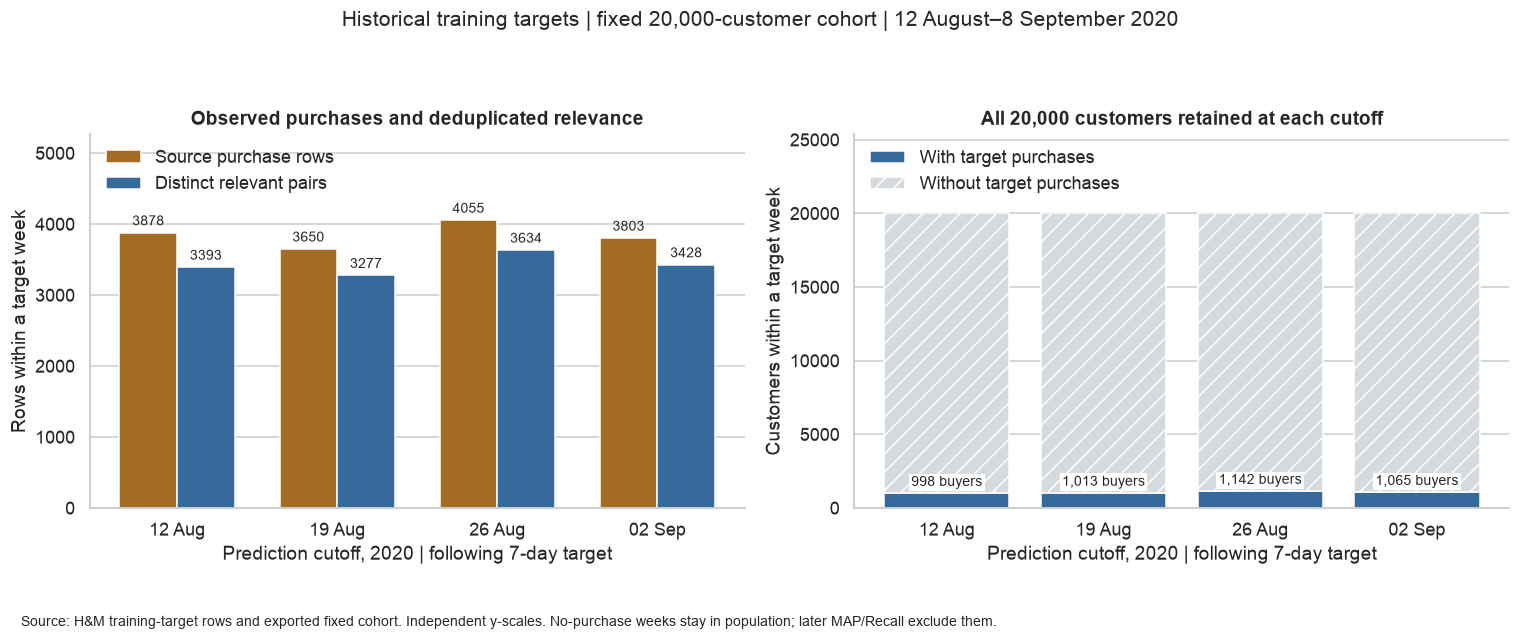

In [9]:
week_labels = [cutoff.strftime("%d %b") for cutoff in training_summary.index]
x_positions = list(range(len(week_labels)))
fig_training_targets, axes = plt.subplots(1, 2, figsize=(14, 5.8))
axes[0].bar([x-0.18 for x in x_positions], training_summary["target_source_rows"], width=0.36, color="#A46B24", label="Source purchase rows")
axes[0].bar([x+0.18 for x in x_positions], training_summary["distinct_customer_article_targets"], width=0.36, color="#356A9A", label="Distinct relevant pairs")
axes[0].set_title("Observed purchases and deduplicated relevance")
axes[0].set_ylabel("Rows within a target week")
axes[0].set_ylim(0, max(training_summary["target_source_rows"].max()*1.3, 1))
axes[0].legend(loc="upper left", frameon=False)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=3, fontsize=9)
buyers = training_summary["customers_with_target_purchases"]
nonbuyers = training_summary["customers_without_target_purchases"]
axes[1].bar(x_positions, buyers, color="#356A9A", label="With target purchases")
axes[1].bar(x_positions, nonbuyers, bottom=buyers, color="#D5DADF", label="Without target purchases", hatch="//")
axes[1].set_title("All 20,000 customers retained at each cutoff")
axes[1].set_ylabel("Customers within a target week")
axes[1].set_ylim(0, len(training_customer_ids)*1.27)
axes[1].legend(loc="upper left", frameon=False)
for x, n_buyers in enumerate(buyers):
    axes[1].text(x, n_buyers+len(training_customer_ids)*0.025, f"{int(n_buyers):,} buyers", ha="center", fontsize=9,
                 bbox={"facecolor":"white", "edgecolor":"none", "pad":1.5})
for ax in axes:
    ax.set_xticks(x_positions, week_labels)
    ax.set_xlabel("Prediction cutoff, 2020 | following 7-day target")
    ax.set_ylim(bottom=0)
    ax.grid(axis="x", visible=False)
sns.despine(fig=fig_training_targets)
fig_training_targets.suptitle("Historical training targets | fixed 20,000-customer cohort | 12 August–8 September 2020", y=0.99, fontsize=14)
fig_training_targets.tight_layout(rect=(0, 0.09, 1, 0.93))
fig_training_targets.text(0.02, 0.025, "Source: H&M training-target rows and exported fixed cohort. Independent y-scales. No-purchase weeks stay in population; later MAP/Recall exclude them.", fontsize=9)
plt.show()

## 7. Export reference targets with provenance

Save a small reference dataset under `data/processed/training_targets/`, already ignored by Git. The content fingerprint includes the schedule, cohort, source manifest, code and runtime. Store typed Parquet, the schedule, source notebook snapshot and a manifest.

Each Parquet is checked against its in-memory source via exact SQL row differences before the final directory is published. An identical export is verified and reused. No earlier features or historical candidate rows are produced by this export.

In [10]:
if not TRAINING_NOTEBOOK_PATH.is_file():
    raise FileNotFoundError("Save notebooks/04_training_dataset.ipynb before exporting.")
saved_training_notebook = json.loads(TRAINING_NOTEBOOK_PATH.read_text())
training_code_cells = [cell["source"] if isinstance(cell["source"], str) else "".join(cell["source"])
                       for cell in saved_training_notebook["cells"] if cell["cell_type"] == "code"]
training_provenance = {
    "spec_version": "training_targets_v1",
    "cohort_sha256": training_cohort_sha256,
    "schedule": training_schedule.astype("string").to_dict(orient="records"),
    "validation_cutoff": str(VALIDATION_CUTOFF.date()),
    "horizon_days": HORIZON_DAYS, "history_days": HISTORY_DAYS, "popularity_days": POPULARITY_DAYS,
    "source_manifest_sha256": file_sha256(source_manifest_path),
    "recorded_raw_files": source_manifest["files"],
    "raw_integrity_check": "Recorded hashes inherited; current sizes checked; raw bytes not rehashed here.",
    "notebook_code_sha256": sha256(json.dumps(training_code_cells, ensure_ascii=False, separators=(",", ":")).encode()).hexdigest(),
    "source_code_sha256": {
        "training_targets": file_sha256(Path(training_targets_module.__file__)),
        "data_io": file_sha256(PROJECT_ROOT / "src/atelier_ai/data_io.py"),
        "temporal": file_sha256(PROJECT_ROOT / "src/atelier_ai/temporal.py"),
    },
    "runtime": {"python": platform.python_version(), "pandas": pd.__version__, "duckdb": duckdb.__version__},
    "dataset_role": "Historical reference relevance and full population; candidate features not yet generated.",
}
training_target_fingerprint = sha256(json.dumps(training_provenance, sort_keys=True, separators=(",", ":")).encode()).hexdigest()
training_target_directory = TRAINING_TARGET_OUTPUT_BASE / f"training_targets_{training_target_fingerprint[:12]}"
TRAINING_TARGET_OUTPUT_BASE.mkdir(parents=True, exist_ok=True)
training_export_reused = training_target_directory.exists()
if not training_export_reused:
    with TemporaryDirectory(prefix=".training-targets-partial-", dir=TRAINING_TARGET_OUTPUT_BASE) as temporary:
        staging = Path(temporary) / "dataset"
        staging.mkdir()
        exported_records = []
        with duckdb.connect(config={"threads": 2, "memory_limit": "512MB"}) as connection:
            for filename, frame in [
                ("target_transactions.parquet", training_target_transactions),
                ("relevance.parquet", training_relevance),
                ("population.parquet", training_population),
            ]:
                connection.register("_target_frame", frame)
                destination = staging / filename
                connection.sql("SELECT * FROM _target_frame").write_parquet(str(destination), compression="zstd")
                differences = connection.execute(
                    "SELECT count(*) FROM ((SELECT * FROM _target_frame EXCEPT ALL SELECT * FROM read_parquet(?)) "
                    "UNION ALL (SELECT * FROM read_parquet(?) EXCEPT ALL SELECT * FROM _target_frame))",
                    [str(destination), str(destination)],
                ).fetchall()[0][0]
                if differences:
                    raise ValueError(f"Target export roundtrip differs: {filename}")
                stored_schema = connection.execute("DESCRIBE SELECT * FROM read_parquet(?)", [str(destination)]).fetchall()
                connection.unregister("_target_frame")
                exported_records.append({"file": filename, "rows": len(frame), "size_bytes": destination.stat().st_size,
                                         "sha256": file_sha256(destination),
                                         "schema": [{"name": row[0], "type": row[1]} for row in stored_schema]})
        training_schedule.to_csv(staging / "schedule.csv", index=False)
        shutil.copyfile(TRAINING_NOTEBOOK_PATH, staging / "pipeline_notebook.ipynb")
        for filename in ["schedule.csv", "pipeline_notebook.ipynb"]:
            destination = staging / filename
            exported_records.append({"file": filename, "size_bytes": destination.stat().st_size,
                                     "sha256": file_sha256(destination)})
        training_target_manifest = {"status": "complete", "fingerprint": training_target_fingerprint,
                                    "provenance": training_provenance, "files": exported_records}
        (staging / "manifest.json").write_text(json.dumps(training_target_manifest, indent=2)+"\n")
        staging.rename(training_target_directory)
training_target_manifest = json.loads((training_target_directory / "manifest.json").read_text())
if training_target_manifest["status"] != "complete" or training_target_manifest["fingerprint"] != training_target_fingerprint:
    raise ValueError("Existing target export has a different identity.")
for record in training_target_manifest["files"]:
    path = training_target_directory / record["file"]
    if path.stat().st_size != record["size_bytes"] or file_sha256(path) != record["sha256"]:
        raise ValueError(f"Target export checksum differs: {record['file']}")
print("Training reference dataset:", training_target_directory)
print("Reused verified export:", training_export_reused)

Training reference dataset: /Users/oumar/Developer/portfolio/atelier-ai-project/data/processed/training_targets/training_targets_8973834a77a7
Reused verified export: False


### Reference-target observations

The four fixed historical weeks contain **15,386 source purchase rows**, deduplicated into **13,732 positive `(cutoff, customer, article)` keys**. All **80,000 customer–week pairs** are retained. Of these, **4,218 have target purchases** and **75,782 have none (94.728%)**. There are **3,336 distinct customers** with at least one purchase across the four weeks; this differs from the count of customer–weeks.

Weekly distinct positive counts are 3,393, 3,277, 3,634 and 3,428. The corresponding numbers of purchasing customers are 998, 1,013, 1,142 and 1,065. These labels do not establish candidate coverage or the positive rate in the future candidate-feature training table.

The complete ten-cell code sequence was executed in a fresh Python process with the project environment. A second source scan using DuckDB matched every retained purchase row, including repetitions. Independent set-based checks matched every relevance key and all 80,000 population counts. Parquet round trips and export reuse passed. The 32 existing tests plus ten new tests passed together (**42 tests**).

The saved section 1–7 outputs agree with these reference observations. The following sections extend the notebook to labelled historical candidates.

## 8. Reuse the validated historical feature implementation

Copy the supplied `recommendation_features.py`, `historical_contexts.py`, updated `feature_export.py` and the two new test files into the project. Restart the kernel and run `python -m pytest -q`.

Eight core functions are extracted unchanged from notebook 03. The policy remains: up to 100 recent purchased articles, up to 100 articles popular within the dominant historical group, then global-popularity fill to 300 distinct candidates. Membership flags can overlap even though the first-addition audit is exclusive.

The feature builder receives only prediction keys and historical lookups. Labels are not inputs. Seventeen numeric/boolean model columns remain separate from identifiers, group audit descriptors and the target column.

In [11]:
import atelier_ai.recommendation_features as recommendation_features_module
import atelier_ai.historical_contexts as historical_contexts_module
import atelier_ai.feature_export as feature_export_module
from atelier_ai.recommendation_features import (
    FEATURE_COLUMNS, EXPECTED_MISSING_FEATURES, feature_contract,
    prepare_feature_tables, build_candidate_pools, build_checked_feature_batch,
    feature_storage_schema,
)
from atelier_ai.historical_contexts import collect_historical_contexts
from atelier_ai.feature_export import export_feature_batches

MAX_CANDIDATES = 300
HISTORY_CANDIDATE_LIMIT = 100
CATEGORY_CANDIDATE_LIMIT = 100
FEATURE_BATCH_CUSTOMERS = 500
TRAINING_STORAGE_SCHEMA = feature_storage_schema(include_label=True)
if len(FEATURE_COLUMNS) != 17 or "label" in FEATURE_COLUMNS:
    raise ValueError("Keep the target outside the declared seventeen model features.")
validation_schema = {entry["name"]: entry["type"] for entry in validation_manifest["schema"]}
if feature_storage_schema() != validation_schema:
    raise ValueError("Training feature storage differs from the established validation schema.")
article_groups = read_source_csv(
    PROJECT_ROOT / "data/raw/hm/articles.csv", columns=["article_id", "product_group_name"]
)
if not article_groups["article_id"].is_unique:
    raise ValueError("Article metadata must contain exactly one row per article.")
print("Model features:", len(FEATURE_COLUMNS))
print("Batch rows:", FEATURE_BATCH_CUSTOMERS * MAX_CANDIDATES)
print("Total expected candidate rows:", len(training_customer_ids) * TRAINING_WEEKS * MAX_CANDIDATES)

Model features: 17
Batch rows: 150000
Total expected candidate rows: 24000000


## 9. Recompute cutoff-specific histories and popularity in one source pass

Keep cohort transaction rows over the union of historical windows, then compute each customer's 180-day history separately at every cutoff. Global recent popularity uses **all** source customers and the seven days strictly before each cutoff. A source row at a cutoff is excluded from that cutoff's features.

These historical windows overlap deliberately. Events may enter a later history only after they have occurred. No validation/test target rows are retained. Source chunks, retained cohort history rows and lookup tables consume memory; this is not a claim of constant total process RAM.

In [12]:
with read_source_chunks(
    PROJECT_ROOT / "data/raw/hm/transactions_train.csv",
    columns=["t_dat", "customer_id", "article_id"], chunk_rows=SOURCE_CHUNK_ROWS,
) as chunks:
    historical_contexts = collect_historical_contexts(
        report_training_scan(chunks), training_customer_ids, training_schedule["cutoff"],
        history_days=HISTORY_DAYS, popularity_days=POPULARITY_DAYS,
    )
historical_context_summary = pd.DataFrame([
    {"cutoff": cutoff,
     "historical_source_rows": int(context["history"]["history_transaction_rows"].sum()),
     "distinct_historical_pairs": len(context["history"]),
     "customers_with_history": context["history"]["customer_id"].nunique(),
     "recent_global_source_rows": int(context["popularity"]["transaction_rows"].sum()),
     "recent_global_articles": len(context["popularity"])}
    for cutoff, context in historical_contexts.items()
]).set_index("cutoff")
print(historical_context_summary.to_string())

Reading source chunk 10...
Reading source chunk 20...
Reading source chunk 30...
Reading source chunk 40...
Reading source chunk 50...
Reading source chunk 60...
            historical_source_rows  distinct_historical_pairs  customers_with_history  recent_global_source_rows  recent_global_articles
cutoff                                                                                                                                  
2020-08-12                  112771                      98010                   10667                     289161                   19482
2020-08-19                  113022                      98192                   10644                     265211                   19446
2020-08-26                  113312                      98398                   10630                     256644                   19976
2020-09-02                  113645                      98750                   10650                     283181                   19614


## 10. Declare training dataset identity and attach labels after features

An explicit `dataset_split="training"` gives historical exports training-prefixed names. The default validation split remains available. The updated exporter reads existing manifests too; a changed exporter/code fingerprint creates a new version on future builds, without replacing old exports.

Save notebook 04 before Run All. Extending its code changes the recorded source identity, so section 7 may create a new reference-target directory with the same target values. Saved outputs and Markdown do not affect code-only identity.

Every labelled batch preserves all candidate rows. It has 23 columns: three prediction keys, two audit descriptors, seventeen model features and one label. No negative sampling or training-group exclusion occurs here.

In [13]:
saved_feature_notebook = json.loads(TRAINING_NOTEBOOK_PATH.read_text())
feature_notebook_code = [cell["source"] if isinstance(cell["source"], str) else "".join(cell["source"])
                         for cell in saved_feature_notebook["cells"] if cell["cell_type"] == "code"]
historical_feature_provenance = {
    "spec_version": "historical_candidate_features_v1",
    "cohort_sha256": training_cohort_sha256,
    "training_target_fingerprint": training_target_fingerprint,
    "source_manifest_sha256": file_sha256(source_manifest_path),
    "recorded_raw_files": source_manifest["files"],
    "raw_integrity_check": "Recorded source hashes inherited; current raw sizes checked; raw bytes not rehashed here.",
    "history_days": HISTORY_DAYS, "popularity_days": POPULARITY_DAYS,
    "history_candidate_limit": HISTORY_CANDIDATE_LIMIT, "category_candidate_limit": CATEGORY_CANDIDATE_LIMIT,
    "candidate_policy": "history_then_category_then_global_fill", "feature_contract": feature_contract.to_dict(orient="records"),
    "notebook_code_sha256": sha256(json.dumps(feature_notebook_code, ensure_ascii=False, separators=(",", ":")).encode()).hexdigest(),
    "source_code_sha256": {
        "recommendation_features": file_sha256(Path(recommendation_features_module.__file__)),
        "historical_contexts": file_sha256(Path(historical_contexts_module.__file__)),
        "feature_export": file_sha256(Path(feature_export_module.__file__)),
        "training_targets": file_sha256(Path(training_targets_module.__file__)),
        "data_io": file_sha256(PROJECT_ROOT / "src/atelier_ai/data_io.py"),
        "temporal": file_sha256(PROJECT_ROOT / "src/atelier_ai/temporal.py"),
    },
    "runtime": training_provenance["runtime"],
    "metadata_assumption": "Broad product group is stable per article ID; historical validity remains unverified.",
    "dataset_role": "All historical candidates with observed-purchase labels; no training eligibility filter or model fitting.",
}
historical_feature_spec_sha256 = sha256(json.dumps(historical_feature_provenance, sort_keys=True, separators=(",", ":")).encode()).hexdigest()
TRAINING_FEATURE_OUTPUT_BASE = Path(os.environ.get(
    "ATELIER_TRAINING_FEATURE_OUTPUT_DIR", PROJECT_ROOT / "data/processed/training_features"
))
training_feature_collection = TRAINING_FEATURE_OUTPUT_BASE / f"historical_v1_{historical_feature_spec_sha256[:12]}"

def make_labelled_batch_builder(relevance_for_cutoff):
    def build_labelled_batch(pairs, tables):
        features = build_checked_feature_batch(pairs, tables)
        labelled = label_candidate_pairs(
            features, relevance_for_cutoff, schedule=training_schedule, customer_ids=training_customer_ids,
            validation_cutoff=VALIDATION_CUTOFF, horizon_days=HORIZON_DAYS,
            history_days=HISTORY_DAYS, popularity_days=POPULARITY_DAYS,
        )
        if not labelled["label"].isin([0, 1]).all():
            raise ValueError("Candidate labels must be observed-purchase zero/one values.")
        return labelled
    return build_labelled_batch

print("Training feature collection:", training_feature_collection)

Training feature collection: /Users/oumar/Developer/portfolio/atelier-ai-project/data/processed/training_features/historical_v1_7c6982b16fed


## 11. Generate and export all four historical candidate datasets

For each cutoff: retrieve historical candidates first, prepare lookup tables, compute and label batches, then verify/export them. Each complete cutoff has 20,000 customers, 6,000,000 rows and 40 partitions. Completed cutoff exports can be reused if a later cutoff fails; the collection manifest is written only after all four pass final checks.

Candidate coverage is measured **after** retrieval against unchanged full reference relevance. Missed positive items are not inserted. Preserve customer–weeks without target purchases and buyer weeks without any retrieved positive; their eventual ranker-training eligibility is a later explicit choice.

In [14]:
historical_feature_exports = {}
retrieval_audit_rows = []
expected_positive_counts = {}
for window in training_schedule.itertuples(index=False):
    cutoff = window.cutoff
    context = historical_contexts[cutoff]
    candidate_pools, retrieval_audit = build_candidate_pools(
        training_customer_ids, context["history"], context["popularity"], article_groups,
        budget=MAX_CANDIDATES, history_limit=HISTORY_CANDIDATE_LIMIT,
        category_limit=CATEGORY_CANDIDATE_LIMIT,
    )
    feature_tables = prepare_feature_tables(
        training_customer_ids, context["history"], context["popularity"], article_groups,
        cutoff=cutoff, history_days=HISTORY_DAYS, popularity_days=POPULARITY_DAYS,
        history_limit=HISTORY_CANDIDATE_LIMIT, category_limit=CATEGORY_CANDIDATE_LIMIT,
        global_limit=MAX_CANDIDATES,
    )
    cutoff_relevance = training_relevance.loc[training_relevance["cutoff"].eq(cutoff)].copy()
    targets_by_customer = cutoff_relevance.groupby("customer_id")["article_id"].agg(set).to_dict()
    expected_positive_counts[cutoff] = {
        customer_id: len(targets.intersection(candidate_pools[customer_id]))
        for customer_id, targets in targets_by_customer.items()
    }
    print(f"Exporting training cutoff {cutoff:%Y-%m-%d}...", flush=True)
    result = export_feature_batches(
        training_customer_ids, candidate_pools, feature_tables,
        make_labelled_batch_builder(cutoff_relevance),
        output_base=training_feature_collection, feature_columns=FEATURE_COLUMNS,
        nullable_features=EXPECTED_MISSING_FEATURES, sql_schema=TRAINING_STORAGE_SCHEMA,
        provenance=historical_feature_provenance, notebook_path=TRAINING_NOTEBOOK_PATH,
        candidates_per_customer=MAX_CANDIDATES, batch_customers=FEATURE_BATCH_CUSTOMERS,
        dataset_split="training",
    )
    historical_feature_exports[cutoff] = result
    retrieval_audit_rows.append({"cutoff": cutoff, **retrieval_audit[["history_added", "category_added", "global_added"]].sum().to_dict()})
    print("Verified:", result["checks"]["rows"], "rows; reused:", result["reused"], flush=True)
    del candidate_pools, feature_tables, retrieval_audit
retrieval_addition_summary = pd.DataFrame(retrieval_audit_rows).set_index("cutoff")
print(retrieval_addition_summary.to_string())

Exporting training cutoff 2020-08-12...
Verified feature partitions: 5; customers: 2,500
Verified feature partitions: 10; customers: 5,000
Verified feature partitions: 15; customers: 7,500
Verified feature partitions: 20; customers: 10,000
Verified feature partitions: 25; customers: 12,500
Verified feature partitions: 30; customers: 15,000
Verified feature partitions: 35; customers: 17,500
Verified feature partitions: 40; customers: 20,000
Verified: 6000000 rows; reused: False
Exporting training cutoff 2020-08-19...
Verified feature partitions: 5; customers: 2,500
Verified feature partitions: 10; customers: 5,000
Verified feature partitions: 15; customers: 7,500
Verified feature partitions: 20; customers: 10,000
Verified feature partitions: 25; customers: 12,500
Verified feature partitions: 30; customers: 15,000
Verified feature partitions: 35; customers: 17,500
Verified feature partitions: 40; customers: 20,000
Verified: 6000000 rows; reused: False
Exporting training cutoff 2020-08-26

## 12. Reconcile stored labels with full reference targets

Read only per-customer aggregates with DuckDB. Verify the number of candidates and positive labels for **every** customer–week against independently computed candidate/target intersections. Coverage denominators retain full target relevance, including missed purchases.

Micro coverage weights every distinct purchased pair equally. Macro coverage averages per-buyer target coverage with equal customer–week weight. Neither is a trained model's MAP@12 or Recall@12. Positive-label share uses all six million candidates per cutoff.

In [15]:
historical_candidate_rows = []
for cutoff, result in historical_feature_exports.items():
    paths = [str(result["directory"] / part["file"]) for part in result["manifest"]["parts"]]
    with duckdb.connect(config={"threads": 2, "memory_limit": "512MB"}) as connection:
        stored_counts = connection.execute(
            "SELECT customer_id, count(*) AS candidate_rows, sum(label) AS positive_rows, "
            "min(label) AS min_label, max(label) AS max_label "
            "FROM read_parquet(?) GROUP BY customer_id", [paths],
        ).df()
    if not stored_counts["candidate_rows"].eq(MAX_CANDIDATES).all():
        raise ValueError("Stored customer candidate counts differ.")
    if not stored_counts[["min_label", "max_label"]].isin([0, 1]).all().all():
        raise ValueError("Stored labels are not binary.")
    population = training_population.loc[training_population["cutoff"].eq(cutoff)].merge(
        stored_counts, on="customer_id", how="left", validate="one_to_one",
    )
    expected = population["customer_id"].map(expected_positive_counts[cutoff]).fillna(0).astype("int64")
    if population["candidate_rows"].isna().any() or not population["positive_rows"].eq(expected).all():
        raise ValueError("Stored labels disagree with reference candidate intersections.")
    buyers = population["n_target_articles"].gt(0)
    positive_rows = int(population["positive_rows"].sum())
    reference_rows = int(population["n_target_articles"].sum())
    candidate_rows = int(population["candidate_rows"].sum())
    historical_candidate_rows.append({
        "cutoff": cutoff, "candidate_rows": candidate_rows, "reference_positive_pairs": reference_rows,
        "retrieved_positive_pairs": positive_rows, "missed_positive_pairs": reference_rows-positive_rows,
        "positive_label_share_pct": 100 * positive_rows / candidate_rows,
        "micro_candidate_coverage_pct": 100 * positive_rows/reference_rows if reference_rows else float("nan"),
        "macro_candidate_coverage_pct": 100 * (population.loc[buyers, "positive_rows"] / population.loc[buyers, "n_target_articles"]).mean(),
        "customer_weeks_without_target": int((~buyers).sum()),
        "buyer_weeks_without_retrieved_positive": int((buyers & population["positive_rows"].eq(0)).sum()),
        "customer_weeks_with_retrieved_positive": int(population["positive_rows"].gt(0).sum()),
        "parquet_mib": result["checks"]["parquet_bytes"] / 1024**2,
    })
training_candidate_summary = pd.DataFrame(historical_candidate_rows).set_index("cutoff")
if int(training_candidate_summary["candidate_rows"].sum()) != 24_000_000:
    raise ValueError("Four complete candidate datasets are required.")
print(training_candidate_summary.to_string(float_format=lambda value: f"{value:.4f}"))

            candidate_rows  reference_positive_pairs  retrieved_positive_pairs  missed_positive_pairs  positive_label_share_pct  micro_candidate_coverage_pct  macro_candidate_coverage_pct  customer_weeks_without_target  buyer_weeks_without_retrieved_positive  customer_weeks_with_retrieved_positive  parquet_mib
cutoff                                                                                                                                                                                                                                                                                                                 
2020-08-12         6000000                      3393                       600                   2793                    0.0100                       17.6835                       17.9784                          19002                                     624                                     374       7.5679
2020-08-19         6000000                      3277            

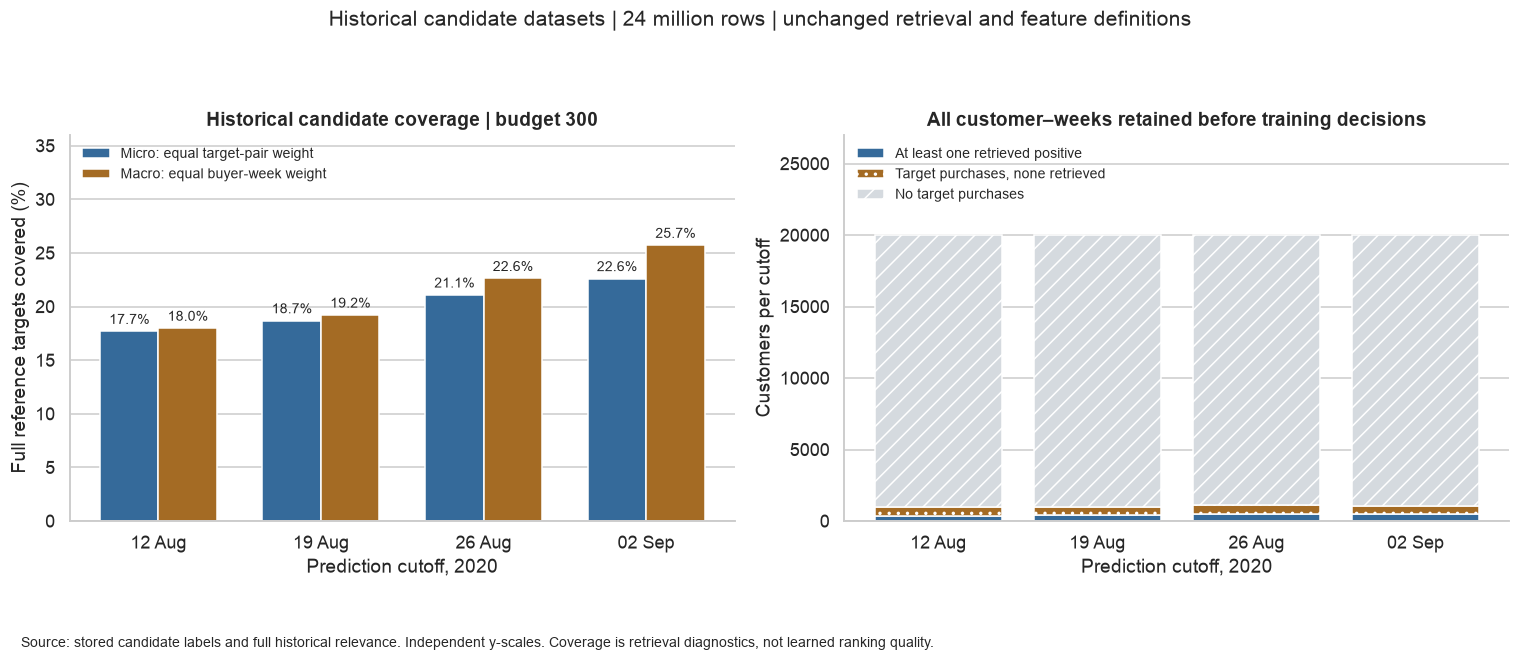

In [16]:
week_labels = [cutoff.strftime("%d %b") for cutoff in training_candidate_summary.index]
x = list(range(len(week_labels)))
fig_historical_candidates, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].bar([value-0.18 for value in x], training_candidate_summary["micro_candidate_coverage_pct"], width=0.36, color="#356A9A", label="Micro: equal target-pair weight")
axes[0].bar([value+0.18 for value in x], training_candidate_summary["macro_candidate_coverage_pct"], width=0.36, color="#A46B24", label="Macro: equal buyer-week weight")
axes[0].set_title("Historical candidate coverage | budget 300")
axes[0].set_ylabel("Full reference targets covered (%)")
coverage_max = training_candidate_summary[["micro_candidate_coverage_pct", "macro_candidate_coverage_pct"]].max().max()
axes[0].set_ylim(0, min(100, coverage_max*1.4))
axes[0].legend(loc="upper left", frameon=False, fontsize=9)
for container in axes[0].containers:
    axes[0].bar_label(container, labels=[f"{bar.get_height():.1f}%" for bar in container], padding=3, fontsize=9)
with_positive = training_candidate_summary["customer_weeks_with_retrieved_positive"]
buyer_without_positive = training_candidate_summary["buyer_weeks_without_retrieved_positive"]
without_target = training_candidate_summary["customer_weeks_without_target"]
axes[1].bar(x, with_positive, color="#356A9A", label="At least one retrieved positive")
axes[1].bar(x, buyer_without_positive, bottom=with_positive, color="#A46B24", hatch="..", label="Target purchases, none retrieved")
axes[1].bar(x, without_target, bottom=with_positive+buyer_without_positive, color="#D5DADF", hatch="//", label="No target purchases")
axes[1].set_title("All customer–weeks retained before training decisions")
axes[1].set_ylabel("Customers per cutoff")
axes[1].set_ylim(0, len(training_customer_ids)*1.35)
axes[1].legend(loc="upper left", frameon=False, fontsize=9)
for ax in axes:
    ax.set_xticks(x, week_labels)
    ax.set_xlabel("Prediction cutoff, 2020")
    ax.grid(axis="x", visible=False)
sns.despine(fig=fig_historical_candidates)
fig_historical_candidates.suptitle("Historical candidate datasets | 24 million rows | unchanged retrieval and feature definitions", y=0.99, fontsize=14)
fig_historical_candidates.tight_layout(rect=(0, 0.10, 1, 0.93))
fig_historical_candidates.text(0.02, 0.025, "Source: stored candidate labels and full historical relevance. Independent y-scales. Coverage is retrieval diagnostics, not learned ranking quality.", fontsize=9)
plt.show()

## 13. Publish the verified four-cutoff collection manifest

Individual cutoff exports become complete only after their file checks. The collection manifest below is created after all four datasets and all customer–week labels reconcile. Existing identical collection metadata is retained; conflicting metadata is rejected.

All 24 million candidate rows are retained. The next milestone must explicitly choose ranker-training groups and any sampling, then consolidate the remaining pipeline/documentation before fitting a model.

In [17]:
training_collection_manifest = {
    "status": "complete", "spec_sha256": historical_feature_spec_sha256,
    "cohort_sha256": training_cohort_sha256, "training_target_fingerprint": training_target_fingerprint,
    "model_features": FEATURE_COLUMNS, "label_column": "label",
    "candidate_rows": int(training_candidate_summary["candidate_rows"].sum()),
    "customer_week_rows": len(training_customer_ids)*TRAINING_WEEKS,
    "datasets": [{"cutoff": str(cutoff.date()), "directory": result["directory"].name,
                  "fingerprint": result["manifest"]["fingerprint"], "rows": result["checks"]["rows"]}
                 for cutoff, result in historical_feature_exports.items()],
    "summary": training_candidate_summary.reset_index().astype({"cutoff":"string"}).to_dict(orient="records"),
    "training_group_filter": "None. No-purchase and zero-retrieved-positive groups retained.",
}
collection_payload = json.dumps(training_collection_manifest, indent=2)+"\n"
collection_manifest_path = training_feature_collection / "collection_manifest.json"
if collection_manifest_path.exists():
    if collection_manifest_path.read_text() != collection_payload:
        raise ValueError("Existing collection metadata differs from verified datasets.")
else:
    collection_manifest_path.write_text(collection_payload)
print("Complete historical candidate collection:", training_feature_collection)
print("Candidate rows:", training_collection_manifest["candidate_rows"])
print("Customer–week rows:", training_collection_manifest["customer_week_rows"])

Complete historical candidate collection: /Users/oumar/Developer/portfolio/atelier-ai-project/data/processed/training_features/historical_v1_7c6982b16fed
Candidate rows: 24000000
Customer–week rows: 80000


## Historical candidate observations

Reference execution produced **24,000,000 candidate rows**, **160 Parquet partitions**, **80,000 customer–week groups**, **17 model features** and a separate observed-purchase label. Parquet partitions total approximately **30.2 MiB**.

Only **2,753 of the 13,732 reference positive pairs** occur among candidates. Positive-label share is approximately **0.01147%** over all candidate rows. Micro coverage by week is **17.68%, 18.68%, 21.08%, 22.61%**; macro coverage is **17.98%, 19.21%, 22.62%, 25.71%**. These are historical retrieval diagnostics, not learned ranking performance. Missing reference positives are retained for coverage/evaluation, not injected into candidates.

Of the 80,000 customer–week groups, **75,782 have no target purchase**, **2,443 have target purchases but no retrieved positive**, and **1,775 have at least one retrieved positive**. All are retained in the exports. Training eligibility, sampling and weighting remain explicit next-step choices; the raw export's imbalance is not the final ranker training distribution.

All four source-history and global-popularity tables match independent DuckDB aggregation of raw transactions. The eight extracted core function bodies match notebook 03. A 150,000-row validation reconstruction matches all 22 stored columns of the established validation export. All 80,000 stored positive counts match candidate/target intersections, and all four exports were verified/reused without rebuilding. The existing 42 tests and eight new tests passed together (**50 tests**).

The model input remains exactly the seventeen declared feature columns; `label`, identifiers and audit descriptors are excluded. The complete seventeen-cell code sequence was run in a fresh Python process using the project environment, rather than a Jupyter kernel. The standalone diagnostic PNG was rendered and visually inspected. The saved section 8–13 outputs agree with the reference observations; the complete on-disk exports have also been independently verified.

Run all sections from the project kernel and save outputs when integrating this extended version.

## 14. Fix the training-only group policy

One ranking group is one `(cutoff, customer_id)` with its 300 generated articles. For the initial binary relevance ranking objective, retain a group only if it contains **at least one label 1 and at least one label 0**. Constant-label groups provide no observed positive-versus-negative order within that group. This is a modelling choice for grouped ranking, not a universal rule for every binary classifier.

| Labels within a group | Initial ranker-training action |
|---|---|
| `[1, 0, 0]` | Keep the complete group |
| `[0, 0, 0]` | Exclude from ranker fitting; preserve in raw exports and audit |
| `[1, 1, 1]` | Exclude from ranker fitting; preserve in raw exports and audit |

Keep **all** candidates in eligible groups. No negative sampling, synthetic oversampling, duplicate positives or extra training weights are introduced. Loss-level group weighting/normalisation remains part of the future ranker configuration.

**Scope:** this target-dependent selection is applied only to historical training data. It changes the training distribution and does not estimate purchase probability across the full population. Validation/test retain all recommendation recipients and their complete reference targets. The existing metric eligibility convention remains unchanged.

Copy `src/atelier_ai/ranking_data.py` and `tests/test_ranking_data.py`, restart the project kernel and run `python -m pytest -q`.

In [18]:
import atelier_ai.ranking_data as ranking_data_module
from atelier_ai.ranking_data import (
    inspect_training_groups, load_eligible_training_rows, prepare_ranker_inputs,
)

if training_collection_manifest["status"] != "complete":
    raise ValueError("Complete all four historical candidate exports first.")
ranker_source_paths = [
    result["directory"] / part["file"]
    for result in historical_feature_exports.values() for part in result["manifest"]["parts"]
]
ranker_group_audit = inspect_training_groups(
    ranker_source_paths, validation_cutoff=VALIDATION_CUTOFF,
    candidates_per_group=MAX_CANDIDATES, dataset_split="training",
).merge(
    training_population[["cutoff", "customer_id", "n_target_articles"]],
    on=["cutoff", "customer_id"], how="left", validate="one_to_one",
)
if len(ranker_group_audit) != len(training_population) or ranker_group_audit["n_target_articles"].isna().any():
    raise ValueError("Audit must retain every historical customer–week.")
if not ranker_group_audit["positive_rows"].le(ranker_group_audit["n_target_articles"]).all():
    raise ValueError("Retrieved positives exceed full reference relevance.")
ranker_group_summary = ranker_group_audit.groupby("cutoff").agg(
    raw_groups=("customer_id", "size"), selected_groups=("eligible", "sum"),
    source_positive_rows=("positive_rows", "sum"),
)
selected_audit = ranker_group_audit.loc[ranker_group_audit["eligible"]]
ranker_group_summary["selected_rows"] = selected_audit.groupby("cutoff")["candidate_rows"].sum()
ranker_group_summary["selected_positive_rows"] = selected_audit.groupby("cutoff")["positive_rows"].sum()
ranker_group_summary["excluded_groups"] = ranker_group_summary["raw_groups"] - ranker_group_summary["selected_groups"]
print(ranker_group_summary.to_string())
print("Selection reasons:\n", ranker_group_audit["reason"].value_counts().to_string())

            raw_groups  selected_groups  source_positive_rows  selected_rows  selected_positive_rows  excluded_groups
cutoff                                                                                                               
2020-08-12       20000              374                   600         112200                     600            19626
2020-08-19       20000              399                   612         119700                     612            19601
2020-08-26       20000              506                   766         151800                     766            19494
2020-09-02       20000              496                   775         148800                     775            19504
Selection reasons:
 reason
all_zero_labels              78225
has_positive_and_negative     1775


## 15. Load only complete eligible groups

DuckDB joins the full Parquet collection with the selected group keys before returning a pandas DataFrame. Thus pandas receives the filtered training subset, not all 24 million rows. Every eligible group keeps all 300 candidates, so no within-group negative sampling occurs.

This explicitly excludes all-zero groups, including both no-purchase weeks and buyer weeks whose purchases were entirely missed by retrieval. Both situations remain visible in the 80,000-row audit. The policy is conditional on observed historical labels and must not be applied when producing recommendations for unknown future outcomes.

In [19]:
ranker_training_rows = load_eligible_training_rows(
    ranker_source_paths, ranker_group_audit, dataset_split="training",
)
if len(ranker_training_rows) != int(ranker_group_summary["selected_rows"].sum()):
    raise ValueError("Selected training row count differs from the group audit.")
if int(ranker_training_rows["label"].sum()) != int(ranker_group_summary["selected_positive_rows"].sum()):
    raise ValueError("Selected positives differ from audited group labels.")
print("Selected candidate rows:", len(ranker_training_rows))
print("Selected positive labels:", int(ranker_training_rows["label"].sum()))
print("Selected negative labels:", int(ranker_training_rows["label"].eq(0).sum()))

Selected candidate rows: 532500
Selected positive labels: 2753
Selected negative labels: 529747


## 16. Prepare aligned X, y and contiguous groups

Sort by prediction cutoff, customer ID, then article ID. All rows of one group stay adjacent. Build:

- `X`: the seventeen declared numeric/boolean historical features in fixed order;
- `y`: observed-purchase labels aligned to those rows;
- `groups`: the number of consecutive rows per customer–week;
- audit keys and group offsets, excluded from X.

For group sizes `[300, 300, ...]`, the first 300 rows belong to the first group, the next 300 to the second, and so on. Their sum must equal the number of X/y rows. This follows the [documented grouped input convention](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMRanker.html); no LightGBM installation or model fitting occurs here.

No scaler, encoder or statistical imputer is fitted. Allowed missing values keep their meaning. The next model must support them or fit any required transformation on training only.

In [20]:
ranker_inputs = prepare_ranker_inputs(
    ranker_training_rows, validation_cutoff=VALIDATION_CUTOFF,
)
X_train = ranker_inputs["X"]
y_train = ranker_inputs["y"]
train_group_sizes = ranker_inputs["groups"]
training_group_index = ranker_inputs["group_index"]
assert X_train.columns.tolist() == FEATURE_COLUMNS
assert "label" not in X_train and "customer_id" not in X_train and "article_id" not in X_train
assert len(X_train) == len(y_train) == int(train_group_sizes.sum())
assert len(training_group_index) == int(ranker_group_summary["selected_groups"].sum())
assert (ranker_inputs["keys"].reset_index(drop=True) == ranker_training_rows[["cutoff", "customer_id", "article_id"]].reset_index(drop=True)).all().all()
ranker_input_summary = pd.Series({
    "training_rows": len(X_train), "model_features": X_train.shape[1],
    "training_groups": len(train_group_sizes), "positive_labels": int(y_train.sum()),
    "negative_labels": int(y_train.eq(0).sum()), "positive_label_share_pct": 100*y_train.mean(),
    "X_dataframe_deep_mib": X_train.memory_usage(deep=True).sum()/1024**2,
}, name="value")
print(ranker_input_summary.to_string())
print("First group offsets:\n", training_group_index.head(3).to_string(index=False))

training_rows               532500.000000
model_features                  17.000000
training_groups               1775.000000
positive_labels               2753.000000
negative_labels             529747.000000
positive_label_share_pct         0.516995
X_dataframe_deep_mib            51.291115
First group offsets:
     cutoff                                                      customer_id  group_size  positive_rows  row_end_exclusive  row_start
2020-08-12 004995f86aedd82f31fde9516781685a0719f6ce4d2f3c623a0b4a3f0160afdc         300              1                300          0
2020-08-12 00f14051bc466787e8fd71acbc5f7f8fa7fc4a2bbd0d7445a343091c7062add4         300              3                600        300
2020-08-12 0133f98cb88f25dce00672600f11a704c681ba6487e21df5e929eb579d9c766c         300              2                900        600


### Inspect the selected training distribution

The positive share changes because constant-label groups are excluded, not because new positives were generated. The selected subset is conditional on the historical training policy. Its class distribution is not the population purchase rate or a calibrated prediction.

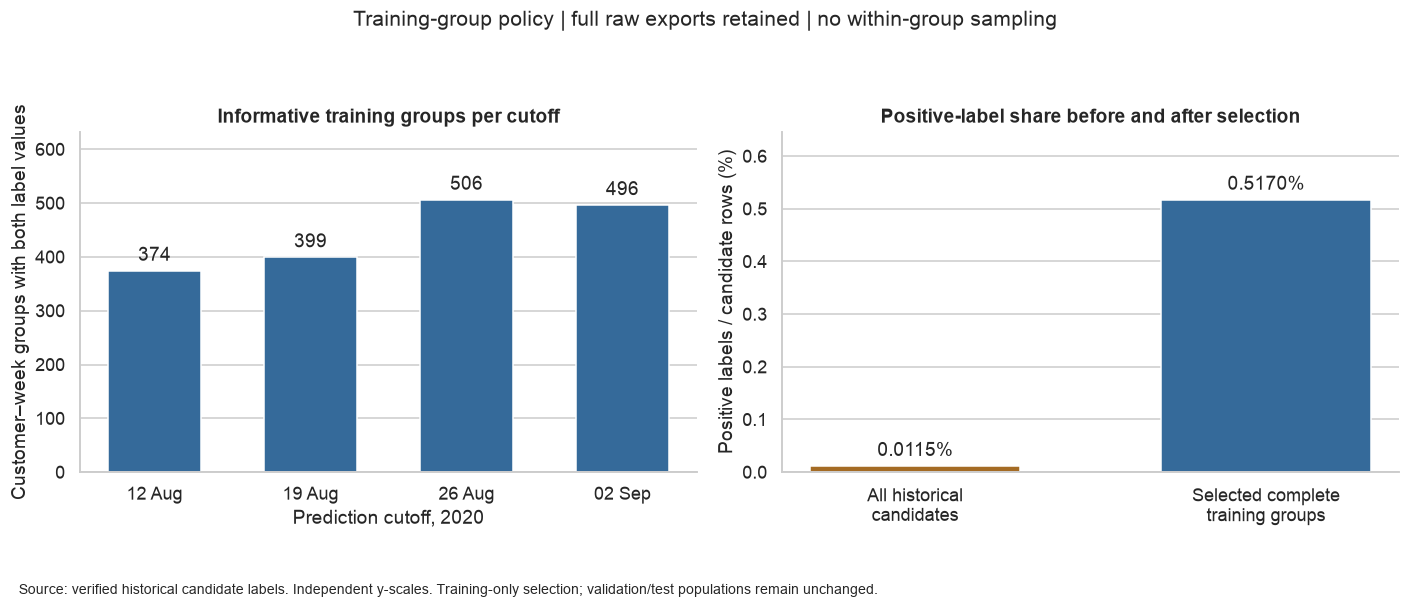

In [21]:
fig_ranker_inputs, axes = plt.subplots(1, 2, figsize=(13, 5.5))
week_labels = [cutoff.strftime("%d %b") for cutoff in ranker_group_summary.index]
axes[0].bar(week_labels, ranker_group_summary["selected_groups"], color="#356A9A", width=0.6)
axes[0].set_title("Informative training groups per cutoff")
axes[0].set_xlabel("Prediction cutoff, 2020")
axes[0].set_ylabel("Customer–week groups with both label values")
axes[0].set_ylim(0, ranker_group_summary["selected_groups"].max()*1.25)
axes[0].bar_label(axes[0].containers[0], fmt="%.0f", padding=4)
raw_positive_share = 100*ranker_group_audit["positive_rows"].sum()/ranker_group_audit["candidate_rows"].sum()
selected_positive_share = 100*y_train.mean()
axes[1].bar(["All historical\ncandidates", "Selected complete\ntraining groups"],
            [raw_positive_share, selected_positive_share], color=["#A46B24", "#356A9A"], width=0.6)
axes[1].set_title("Positive-label share before and after selection")
axes[1].set_ylabel("Positive labels / candidate rows (%)")
axes[1].set_ylim(0, selected_positive_share*1.25)
axes[1].bar_label(axes[1].containers[0], labels=[f"{raw_positive_share:.4f}%", f"{selected_positive_share:.4f}%"], padding=4)
for ax in axes:
    ax.grid(axis="x", visible=False)
sns.despine(fig=fig_ranker_inputs)
fig_ranker_inputs.suptitle("Training-group policy | full raw exports retained | no within-group sampling", fontsize=14, y=0.99)
fig_ranker_inputs.tight_layout(rect=(0, 0.10, 1, 0.93))
fig_ranker_inputs.text(0.02, 0.025, "Source: verified historical candidate labels. Independent y-scales. Training-only selection; validation/test populations remain unchanged.", fontsize=9)
plt.show()

## 17. Export the selected training rows and group contract

Store the selected rows, ordered group index and complete 80,000-group eligibility audit. X and y can be reconstructed from the selected Parquet using the recorded feature order; do not duplicate a second independent set of X/y files.

The manifest records the source collection, training policy, module/notebook hashes and shapes. Files are checked by exact Parquet roundtrip and checksums. No validation/test labels are read by this selection/export step. The full upstream 24-million-row collection remains intact.

In [22]:
ranker_notebook_path = Path(os.environ.get("ATELIER_RANKER_NOTEBOOK", TRAINING_NOTEBOOK_PATH))
saved_ranker_notebook = json.loads(ranker_notebook_path.read_text())
ranker_code = [cell["source"] if isinstance(cell["source"], str) else "".join(cell["source"])
               for cell in saved_ranker_notebook["cells"] if cell["cell_type"] == "code"]
ranker_provenance = {
    "spec_version": "ranker_training_v1", "dataset_split": "training",
    "source_collection_manifest_sha256": file_sha256(collection_manifest_path),
    "source_collection_spec_sha256": training_collection_manifest["spec_sha256"],
    "policy": "Keep complete groups with at least one label 1 and at least one label 0.",
    "negative_sampling": "none", "additional_sample_weights": "none at preparation time",
    "feature_columns": FEATURE_COLUMNS, "label_column": "label", "group_keys": ["cutoff", "customer_id"],
    "row_order": ["cutoff", "customer_id", "article_id"],
    "validation_cutoff": str(VALIDATION_CUTOFF.date()),
    "training_rows": len(X_train), "training_groups": len(train_group_sizes),
    "positive_labels": int(y_train.sum()), "audit_groups": len(ranker_group_audit),
    "ranking_data_source_sha256": file_sha256(Path(ranking_data_module.__file__)),
    "notebook_code_sha256": sha256(json.dumps(ranker_code, ensure_ascii=False, separators=(",", ":")).encode()).hexdigest(),
    "runtime": training_provenance["runtime"],
}
ranker_fingerprint = sha256(json.dumps(ranker_provenance, sort_keys=True, separators=(",", ":")).encode()).hexdigest()
ranker_output_base = Path(os.environ.get("ATELIER_RANKER_OUTPUT_DIR", PROJECT_ROOT/"data/processed/ranker_training"))
ranker_dataset_directory = ranker_output_base/f"ranker_v1_{ranker_fingerprint[:12]}"
ranker_output_base.mkdir(parents=True, exist_ok=True)
ranker_export_reused = ranker_dataset_directory.exists()
if not ranker_export_reused:
    with TemporaryDirectory(prefix=".ranker-partial-", dir=ranker_output_base) as temporary:
        staging = Path(temporary)/"dataset"
        staging.mkdir()
        records = []
        with duckdb.connect(config={"threads":2, "memory_limit":"512MB"}) as connection:
            for filename, frame in [("training_rows.parquet",ranker_training_rows),
                                    ("groups.parquet",training_group_index),
                                    ("group_audit.parquet",ranker_group_audit)]:
                connection.register("_ranker_frame",frame)
                destination=staging/filename
                connection.sql("SELECT * FROM _ranker_frame").write_parquet(str(destination),compression="zstd")
                differences=connection.execute(
                    "SELECT count(*) FROM ((SELECT * FROM _ranker_frame EXCEPT ALL SELECT * FROM read_parquet(?)) "
                    "UNION ALL (SELECT * FROM read_parquet(?) EXCEPT ALL SELECT * FROM _ranker_frame))",
                    [str(destination),str(destination)],
                ).fetchall()[0][0]
                if differences:
                    raise ValueError(f"Ranker export roundtrip differs: {filename}")
                connection.unregister("_ranker_frame")
                records.append({"file":filename,"rows":len(frame),"size_bytes":destination.stat().st_size,
                                "sha256":file_sha256(destination)})
        shutil.copyfile(ranker_notebook_path,staging/"pipeline_notebook.ipynb")
        snapshot=staging/"pipeline_notebook.ipynb"
        records.append({"file":snapshot.name,"size_bytes":snapshot.stat().st_size,"sha256":file_sha256(snapshot)})
        ranker_manifest={"status":"complete","fingerprint":ranker_fingerprint,"provenance":ranker_provenance,"files":records}
        (staging/"manifest.json").write_text(json.dumps(ranker_manifest,indent=2)+"\n")
        staging.rename(ranker_dataset_directory)
ranker_manifest=json.loads((ranker_dataset_directory/"manifest.json").read_text())
if ranker_manifest["status"]!="complete" or ranker_manifest["fingerprint"]!=ranker_fingerprint:
    raise ValueError("Ranker export identity differs.")
for record in ranker_manifest["files"]:
    path=ranker_dataset_directory/record["file"]
    if path.stat().st_size!=record["size_bytes"] or file_sha256(path)!=record["sha256"]:
        raise ValueError(f"Ranker export checksum differs: {record['file']}")
print("Ranker training dataset:",ranker_dataset_directory)
print("Reused verified export:",ranker_export_reused)

Ranker training dataset: /Users/oumar/Developer/portfolio/atelier-ai-project/data/processed/ranker_training/ranker_v1_5e8154a40689
Reused verified export: False
